In [12]:
using CSV, DataFrames
using Plots
using LinearAlgebra
using Statistics
using LaTeXStrings

In [13]:
#Cargamos el df completo

full_df = CSV.read("simulation_results/c6e_run_moments.csv", DataFrame);
full_df

Row,run_id,Dm,De,L,delta,T,c_star,c6e_mean,replicate,sim,m,mAbs,m2,m4,m_final,ell_ahl
,DataStri…,Float64,Float64,Int64,Float64,Float64,Float64,Float64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,L016_De0.01_d-0.30_r0_sb5d477b0,0.01,0.01,16,-0.3,0.7,0.0114787,0.00803509,0,1,-0.921875,0.921875,0.849854,0.722251,-0.921875,1.29099
2,L016_De0.01_d-0.30_r1_s2d43ba31,0.01,0.01,16,-0.3,0.7,0.0114787,0.00803509,1,2,-0.945312,0.945312,0.893616,0.798549,-0.945312,1.29099
3,L016_De0.01_d-0.30_r2_sff9ff6bc,0.01,0.01,16,-0.3,0.7,0.0114787,0.00803509,2,3,-0.914062,0.914062,0.83551,0.698077,-0.914062,1.29099
4,L016_De0.01_d-0.30_r3_s29b3429b,0.01,0.01,16,-0.3,0.7,0.0114787,0.00803509,3,4,-0.945312,0.945312,0.893616,0.798549,-0.945312,1.29099
5,L016_De0.01_d-0.30_r4_s3c1ec7dc,0.01,0.01,16,-0.3,0.7,0.0114787,0.00803509,4,5,-0.9375,0.9375,0.878906,0.772476,-0.9375,1.29099
6,L016_De0.01_d-0.20_r0_s2e6bb31e,0.01,0.01,16,-0.2,0.8,0.0114787,0.00918295,0,1,-0.710938,0.710938,0.505432,0.255462,-0.710938,1.29099
7,L016_De0.01_d-0.20_r1_s28491873,0.01,0.01,16,-0.2,0.8,0.0114787,0.00918295,1,2,-0.726562,0.726562,0.527893,0.278671,-0.726562,1.29099
8,L016_De0.01_d-0.20_r2_s09467b4e,0.01,0.01,16,-0.2,0.8,0.0114787,0.00918295,2,3,-0.65625,0.65625,0.430664,0.185472,-0.65625,1.29099
9,L016_De0.01_d-0.20_r3_s52c7117f,0.01,0.01,16,-0.2,0.8,0.0114787,0.00918295,3,4,-0.710938,0.710938,0.505432,0.255462,-0.710938,1.29099


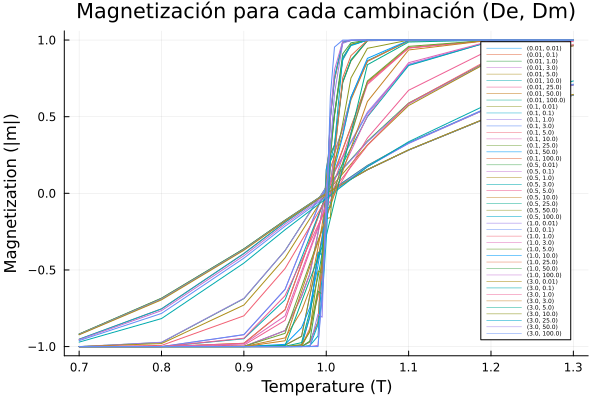

In [14]:
# Si consideramos De y Dm como los parámetros iniciales, entonces tenemos varias combinaciones posibles

df2 = combine(  # df con el promedio sobre las filas sobre cada tupla (L, T, De, Dm)
    groupby(full_df, [:L, :T, :De, :Dm]),
    :m2 => mean => :m2_mean,
    :m4 => mean => :m4_mean,
    :m => mean => :m_mean,
    :mAbs => mean => :mAbs_mean
)

function binder_cumulant(m4, m2)
    return 1 - m4 / (3 * m2^2)
end

function magnetic_susceptibility(L, T, m2, m)
    return (L^2 / T) * (m2 - m^2)
end

df2.U = binder_cumulant.(
    df2.m4_mean,
    df2.m2_mean
)

df64 = df2[df2.L .== 64, :]

p = plot(
    title = "Magnetización para cada cambinación (De, Dm)",
    xlabel = "Temperature (T)",
    ylabel = "Magnetization (|m|)",
    legend = :topright,
    legendfontsize = 4,
    linewidth = 8,
    grid = true,
)

for row in eachrow(unique(df64, [:De, :Dm]))
    De = row.De
    Dm = row.Dm
    filtered_T = df64[df64.De .== row.De .&& df64.Dm .== row.Dm, :].T
    filtered_m = df64[df64.De .== row.De .&& df64.Dm .== row.Dm, :].m_mean
    plot!(p, filtered_T, filtered_m, label="($Dm, $De)")
end

p

In [22]:
# Podemos elegir una combinación particular de (Dm, De), es decir unas parámetros iniciales particulares

filtered_df = full_df[full_df.Dm .== 0.1 .&& full_df.De .== 0.1, :] #aqui elegimos ambos 0.1



df = combine(
    groupby(filtered_df, [:L, :T]),
    :m2 => mean => :m2_mean,
    :m4 => mean => :m4_mean,
    :m => mean => :m_mean,
    :mAbs => mean => :mAbs_mean
)

function binder_cumulant(m4, m2)
    return 1 - m4 / (3 * m2^2)
end

function magnetic_susceptibility(L, T, m2, m)
    return (L^2 / T) * (m2 - m^2)
end

df.U = binder_cumulant.(
    df.m4_mean,
    df.m2_mean
)

df.chi = magnetic_susceptibility.(
    df.L,
    df.T,
    df.m2_mean,
    df.m_mean
)

df.chi_abs = magnetic_susceptibility.(
    df.L,
    df.T,
    df.m2_mean,
    df.mAbs_mean
)

df

Row,L,T,m2_mean,m4_mean,m_mean,mAbs_mean,U,chi,chi_abs
,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,16,0.7,0.9146,0.837172,-0.95625,0.95625,0.666396,0.0678571,0.0678571
2,16,0.8,0.585291,0.346077,-0.764062,0.764062,0.663249,0.479687,0.479687
3,16,0.9,0.187878,0.0357143,-0.432812,0.432812,0.662739,0.156944,0.156944
4,16,0.95,0.0354736,0.00173929,-0.178125,0.178125,0.539278,1.00921,1.00921
5,16,1.0,0.00299072,1.78583e-5,0.0109375,0.0484375,0.334472,0.735,0.165
6,16,1.05,0.0201538,0.00047287,0.139063,0.139063,0.611934,0.19881,0.19881
7,16,1.1,0.127429,0.0181545,0.351562,0.351562,0.62733,0.892045,0.892045
8,16,1.2,0.336768,0.116619,0.578125,0.578125,0.657242,0.541667,0.541667
9,16,1.3,0.544824,0.298816,0.7375,0.7375,0.66444,0.180769,0.180769


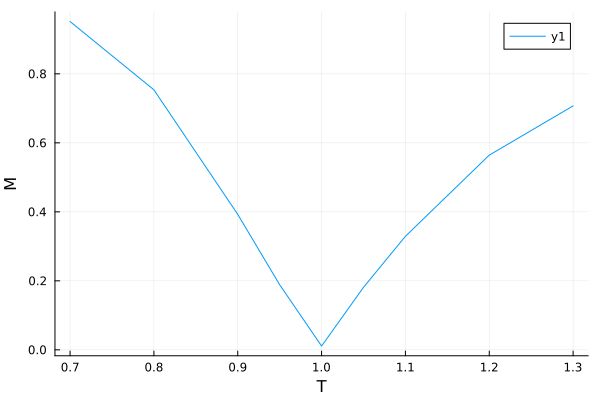

In [ ]:
# Por ejemplo, veamos como se ve la magnetización para un tamaño particlar L = 64

df_L = df[df.L .== 64, :]


plot(df_L.T, df_L.mAbs_mean, xlabel="T", ylabel="M")



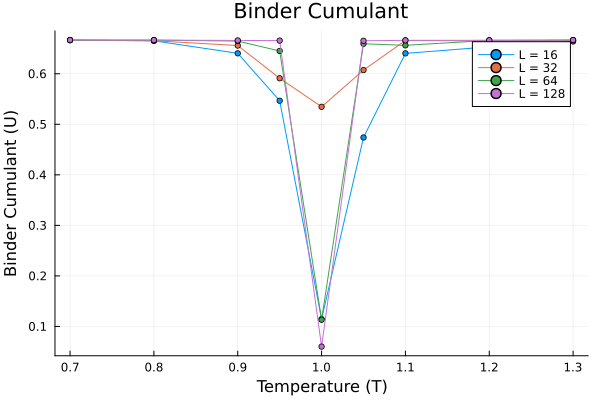

In [17]:
p = plot(
    title = "Binder Cumulant",
    xlabel = "Temperature (T)",
    ylabel = "Binder Cumulant (U)",
    legend = :topright,
    linewidth = 8,
    grid = true,
)

for L in [16, 32, 64, 128]
    df_L = df[df.L .== L,:]
    sort!(df_L, :T)

    plot!(p, df_L.T, df_L.U , label = "L = $L", marker=:circ, markersize=3)
end


p

# ?

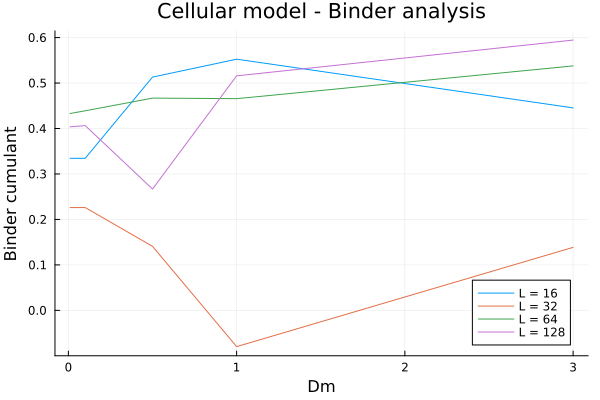

In [ ]:
#intento de hacerlo con Dm en vez de T

df = CSV.read("simulation_results/c6e_run_moments.csv", DataFrame);


filtered = df[
    (df.De .== 0.1) .&
    (df.delta .== 0.0), :
]
binder_df = combine(
    groupby(filtered, [:L, :Dm]),
    :m2 => mean => :mean_m2,
    :m4 => mean => :mean_m4
)


binder_df.U = binder_cumulant.(binder_df.mean_m4, binder_df.mean_m2)

p = plot(
    xlabel = "Dm",
    ylabel = "Binder cumulant",
    title = "Binder analysis"
)

for L in sort(unique(binder_df.L))
    sub = sort(binder_df[binder_df.L .== L, :], :Dm)
    plot!(p, sub.Dm, sub.U, label = "L = $L")
end

display(p)
